In [1]:
import os
import sys

import anndata as ad
import matplotlib.pyplot as plt

# env_site_packages = "/omics/odcf/analysis/OE0290_projects/heroes-aya_pools/AG_Thongjuea/Code/10x_multiomics/Selina/env/scanpy_env/lib/python3.14/site-packages"
# sys.path.remove(env_site_packages)
# sys.path.insert(0, env_site_packages)
import numpy as np
import pandas as pd
import scanpy as sc

import myutils


In [2]:
workspace,experiment=myutils.workspace()
data_dir = workspace/"experiment02-PBMC/results/scanpy_workflow"
data_file = data_dir / 'pbmc3k_scanpy_annotated_retro.h5ad'
assert data_file.exists()

In [3]:
adata = ad.read_h5ad(data_file)
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier', 'leiden', 'celltype'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'scaled'
    obsp: 'connectivities', 'distances'

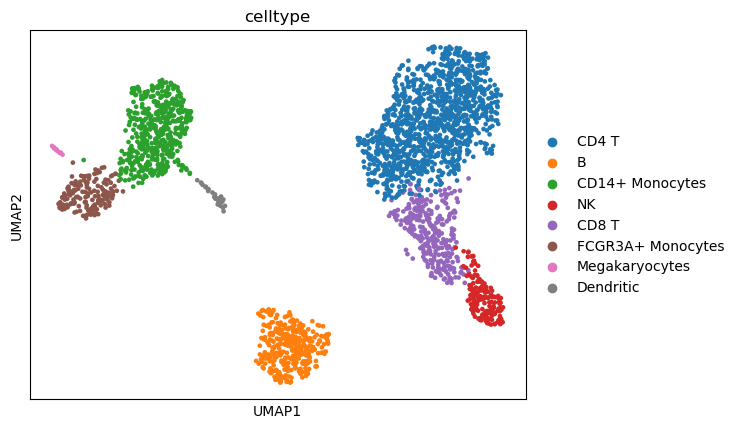

In [4]:
sc.pl.umap(adata, color="celltype")

In [4]:
np.random.seed(42)
n_cells = int(adata.n_obs * 0.3)
selected_idx = np.random.choice(adata.n_obs, n_cells, replace=False)
adata.obs['str_batch'] = '1'
batch_1_cells = adata.obs_names[selected_idx]
adata.obs.loc[batch_1_cells, 'str_batch'] = '0'


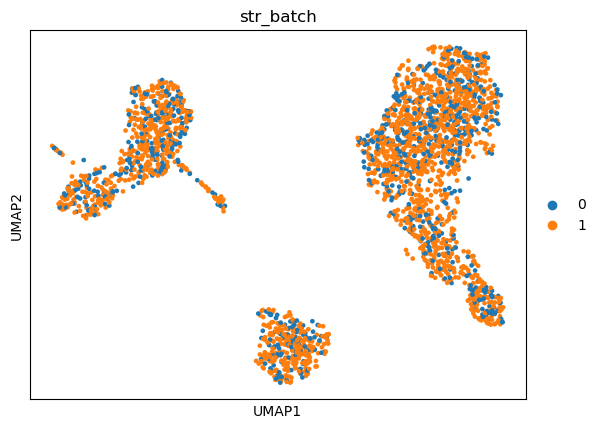

In [5]:
sc.pl.umap(adata, color="str_batch")

In [6]:
print(sum(adata.obs.str_batch == '0') / adata.n_obs, sum(adata.obs.str_batch == '1') / adata.n_obs)
print(sum(adata.obs.str_batch == '0'),sum(adata.obs.str_batch == '1'))

0.2998483699772555 0.7001516300227445
791 1847


In [8]:
adata.write_h5ad(experiment/'data/pbmc3k_scanpy_annotated_batches.h5ad')

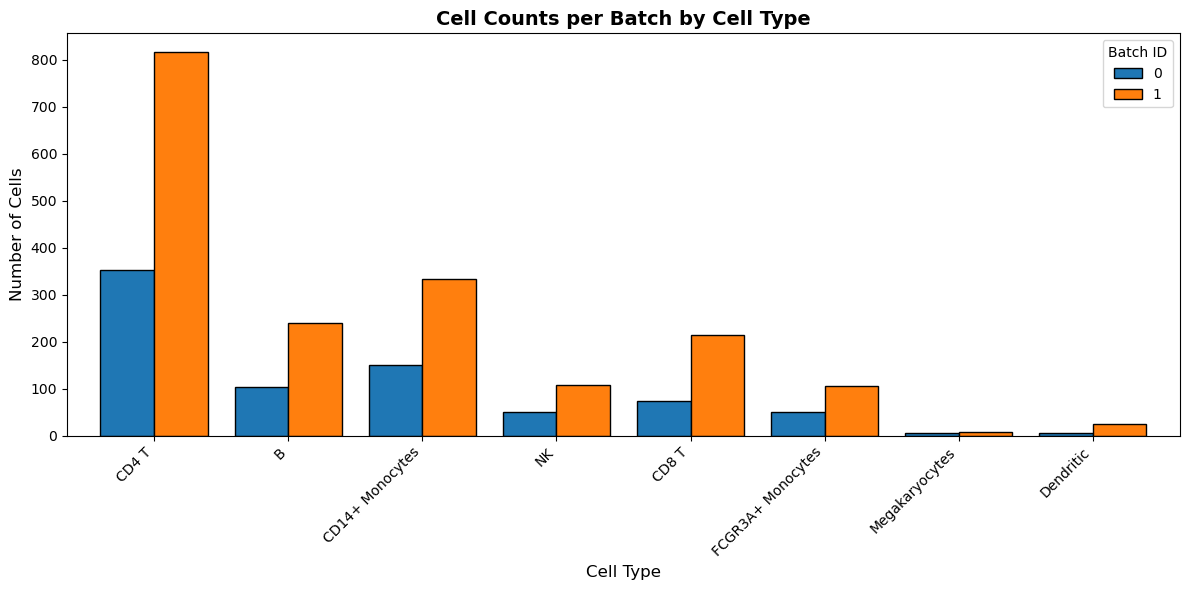

In [10]:
cell_counts = pd.crosstab(adata.obs['celltype'], adata.obs['str_batch'])
cell_counts.plot(kind='bar', stacked=False, figsize=(12, 6), edgecolor='black', width=0.8)

# 3. Add layout styling
plt.title("Cell Counts per Batch by Cell Type", fontsize=14, fontweight='bold')
plt.xlabel("Cell Type", fontsize=12)
plt.ylabel("Number of Cells", fontsize=12)
plt.xticks(rotation=45, ha='right')  # Tilts the labels so they don't overlap
plt.legend(title="Batch ID")
plt.tight_layout()

plt.show()